[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/14-deployment-and-llmops/notebooks/03-observability-and-monitoring.ipynb)

# 03 · Observability and monitoring

**What you will learn**

1. Build a tiny **tracer** from scratch to see that a trace is just nested, timed records.
2. See the equivalent **Langfuse** code (runs only if keys are set).
3. Simulate a week of traffic and compute the four key numbers: **latency percentiles, error rate, token cost, drift**.
4. Draw a monitoring **dashboard** with matplotlib and write simple **alert** rules.
5. Run a tiny offline **eval** and attach scores to traces.

**Words used below**
- **Trace** — the full record of one request. **Span** — one timed step in it. **Generation** — a span that is an LLM call (with tokens and cost).
- **p95 latency** — the time 95% of requests are faster than.
- **Drift** — inputs or outputs slowly changing compared with a normal "baseline" period.

## Step 1 — a tracer in 30 lines

A **context manager** (the `with ...:` block) runs setup code on entry and cleanup code on exit. We use it to start a stopwatch when a step begins and record the duration when it ends. A stack remembers which span is the "parent" so spans nest.

In [1]:
import time, uuid, json
from contextlib import contextmanager

TRACES = []          # finished traces end up here
_stack = []          # the span we are currently inside

@contextmanager
def span(name, kind="span", **attrs):
    node = {"id": uuid.uuid4().hex[:6], "name": name, "kind": kind, "attrs": attrs, "children": []}
    if _stack:
        _stack[-1]["children"].append(node)      # nest under the current span
    _stack.append(node)
    t0 = time.perf_counter()
    try:
        yield node
    except Exception as e:
        node["error"] = repr(e); raise
    finally:
        node["ms"] = round((time.perf_counter() - t0) * 1000, 1)
        _stack.pop()
        if not _stack:
            TRACES.append(node)                  # outermost span finished -> a whole trace

def show(node, depth=0):
    extra = {k: v for k, v in node["attrs"].items()}
    print("  " * depth + f"{node['kind'].upper():10s} {node['name']:14s} {node['ms']:7.1f} ms  {extra}")
    for c in node["children"]:
        show(c, depth + 1)
print("tracer ready")

tracer ready


## Step 2 — trace a pretend RAG request

A fake "answer a question" pipeline with three steps: guardrails, retrieval, and an LLM call. The LLM span records model, tokens and cost — exactly the fields Langfuse stores for a generation.

In [2]:
import random
random.seed(1)
PRICE_IN, PRICE_OUT = 1.0, 5.0         # example USD per 1M tokens (always check the provider's pricing page)

def answer(question):
    with span("answer-question", user="u42") as root:
        with span("guardrails"):
            time.sleep(0.005)
        with span("retrieve", kind="retriever", k=3) as r:
            time.sleep(0.03); r["attrs"]["docs"] = ["doc-12", "doc-40", "doc-7"]
        with span("llm-call", kind="generation", model="demo-model") as g:
            time.sleep(0.08)
            tin, tout = 400 + len(question) // 4, random.randint(40, 120)
            g["attrs"].update(tokens_in=tin, tokens_out=tout,
                              cost_usd=round(tin / 1e6 * PRICE_IN + tout / 1e6 * PRICE_OUT, 6))
        root["attrs"]["output"] = "Docker packages an app with everything it needs."
    return TRACES[-1]

show(answer("What is Docker?"))

SPAN       answer-question   115.8 ms  {'user': 'u42', 'output': 'Docker packages an app with everything it needs.'}
  SPAN       guardrails         5.1 ms  {}
  RETRIEVER  retrieve          30.2 ms  {'k': 3, 'docs': ['doc-12', 'doc-40', 'doc-7']}
  GENERATION llm-call          80.2 ms  {'model': 'demo-model', 'tokens_in': 403, 'tokens_out': 57, 'cost_usd': 0.000688}


## Step 3 — the same thing with Langfuse (guarded)

**Langfuse** stores traces like ours on a server and shows them as clickable trees, with cost dashboards and eval scores. It can be used as a hosted **cloud** service or **self-hosted** with Docker on your own servers.

The code needs three environment variables: `LANGFUSE_PUBLIC_KEY`, `LANGFUSE_SECRET_KEY`, `LANGFUSE_HOST`. Without them the cell prints a message and moves on. (Tested with the langfuse 5.x SDK; check the docs, the API changes between major versions.)

In [3]:
import os
if all(os.getenv(k) for k in ("LANGFUSE_PUBLIC_KEY", "LANGFUSE_SECRET_KEY", "LANGFUSE_HOST")):
    from langfuse import get_client           # pip install langfuse
    lf = get_client()
    with lf.start_as_current_observation(name="answer-question", as_type="span", input="What is Docker?") as root:
        with lf.start_as_current_observation(name="llm-call", as_type="generation", model="demo-model") as gen:
            gen.update(output="Docker packages apps.", usage_details={"input": 410, "output": 60})
        root.score_trace(name="user_feedback", value=1)
    lf.flush()
    print("sent to Langfuse")
else:
    print("Langfuse keys not set - using our home-made tracer above instead.")

Langfuse keys not set - using our home-made tracer above instead.


## Step 4 — simulate a week of traffic

We generate one row per request for 7 days. Built in on purpose:
- daytime peaks,
- an **outage** on day 5 (errors and slow responses),
- **drift** on day 6 (users start pasting long documents → longer prompts → higher cost).

`numpy`'s random generator with a fixed **seed** gives the same "random" data every run, so everyone in class sees the same numbers.

In [4]:
import numpy as np, pandas as pd
rng = np.random.default_rng(42)

rows = []
start = pd.Timestamp("2026-11-01")
for hour in range(24 * 7):
    t = start + pd.Timedelta(hours=hour)
    n = rng.poisson(40 * (1 + 0.6 * np.sin((t.hour - 8) / 24 * 2 * np.pi)))   # requests this hour
    outage = 100 <= hour < 106
    drift = hour >= 130
    for _ in range(n):
        latency = rng.lognormal(mean=np.log(800), sigma=0.35) * (2.5 if outage else 1)
        error = rng.random() < (0.09 if outage else 0.01)
        tin = int(rng.normal(530 if drift else 350, 40))
        tout = int(rng.normal(150, 30))
        rows.append({"time": t + pd.Timedelta(seconds=int(rng.integers(0, 3600))),
                     "latency_ms": latency, "error": error, "tokens_in": tin, "tokens_out": tout,
                     "feature": rng.choice(["chat", "summarise", "search"], p=[0.6, 0.25, 0.15])})
df = pd.DataFrame(rows).sort_values("time").reset_index(drop=True)
df["cost_usd"] = df.tokens_in / 1e6 * PRICE_IN + df.tokens_out / 1e6 * PRICE_OUT
print(len(df), "requests"); df.head()

6687 requests


,time,latency_ms,error,tokens_in,tokens_out,feature,cost_usd
0,2026-11-01 00:03:29,840.889900,False,332,154,summarise,0.001102
1,2026-11-01 00:03:49,786.142174,False,322,186,search,0.001252
2,2026-11-01 00:04:45,1349.974776,False,388,99,summarise,0.000883
3,2026-11-01 00:05:24,948.661550,False,350,164,summarise,0.001170
4,2026-11-01 00:06:22,717.907290,False,323,139,summarise,0.001018


## Step 5 — latency: why percentiles beat averages

The **mean** (average) is pulled around by a few extreme values and hides how bad the slow tail is. **p50** (median) is the typical request; **p95** and **p99** show what the unluckiest users feel.

In [5]:
lat = df.latency_ms
print(f"mean {lat.mean():7.0f} ms")
for p in [50, 90, 95, 99]:
    print(f"p{p:<3d} {np.percentile(lat, p):7.0f} ms")
print(f"max  {lat.max():7.0f} ms")

mean     882 ms
p50      807 ms
p90     1316 ms
p95     1529 ms
p99     2221 ms
max     4374 ms


## Step 6 — error rate and cost, overall and per feature

`groupby` splits the table by feature and summarises each group. Cost per feature tells you *where* the money goes — the first question any manager asks.

In [6]:
summary = df.groupby("feature").agg(requests=("error", "size"),
                                    error_rate=("error", "mean"),
                                    p95_ms=("latency_ms", lambda s: np.percentile(s, 95)),
                                    cost_usd=("cost_usd", "sum"))
print(f"overall error rate {df.error.mean():.2%}, total cost ${df.cost_usd.sum():.2f} for the week")
summary.round(4)

overall error rate 1.38%, total cost $7.61 for the week


,requests,error_rate,p95_ms,cost_usd
feature,,,,
chat,3990,0.0143,1526.8655,4.5278
search,1006,0.0109,1475.7758,1.1504
summarise,1691,0.0142,1567.3499,1.9365


## Step 7 — hourly metrics for the dashboard

`resample("h")` groups rows into one-hour buckets so we can plot a time series.

In [7]:
hourly = df.set_index("time").resample("h").agg(
    requests=("error", "size"), error_rate=("error", "mean"),
    p50=("latency_ms", "median"), p95=("latency_ms", lambda s: s.quantile(0.95) if len(s) else np.nan),
    prompt_tokens=("tokens_in", "mean"), cost_usd=("cost_usd", "sum"))
hourly.head()

,requests,error_rate,p50,p95,prompt_tokens,cost_usd
time,,,,,,
2026-11-01 00:00:00,23,0.0,982.194686,1396.266715,340.434783,0.024435
2026-11-01 01:00:00,24,0.0,704.489582,1355.620897,341.250000,0.026170
2026-11-01 02:00:00,12,0.0,924.267866,1276.171146,339.083333,0.013609
2026-11-01 03:00:00,18,0.0,781.473010,1293.631906,344.055556,0.019153
2026-11-01 04:00:00,21,0.0,792.791079,1270.090335,355.380952,0.023813


## Step 8 — draw the dashboard

Four panels: traffic + error rate, latency percentiles against a **Service Level Objective (SLO)** line, cost per day, and the drift signal (prompt length) against a baseline band. Look for the outage and the drift.

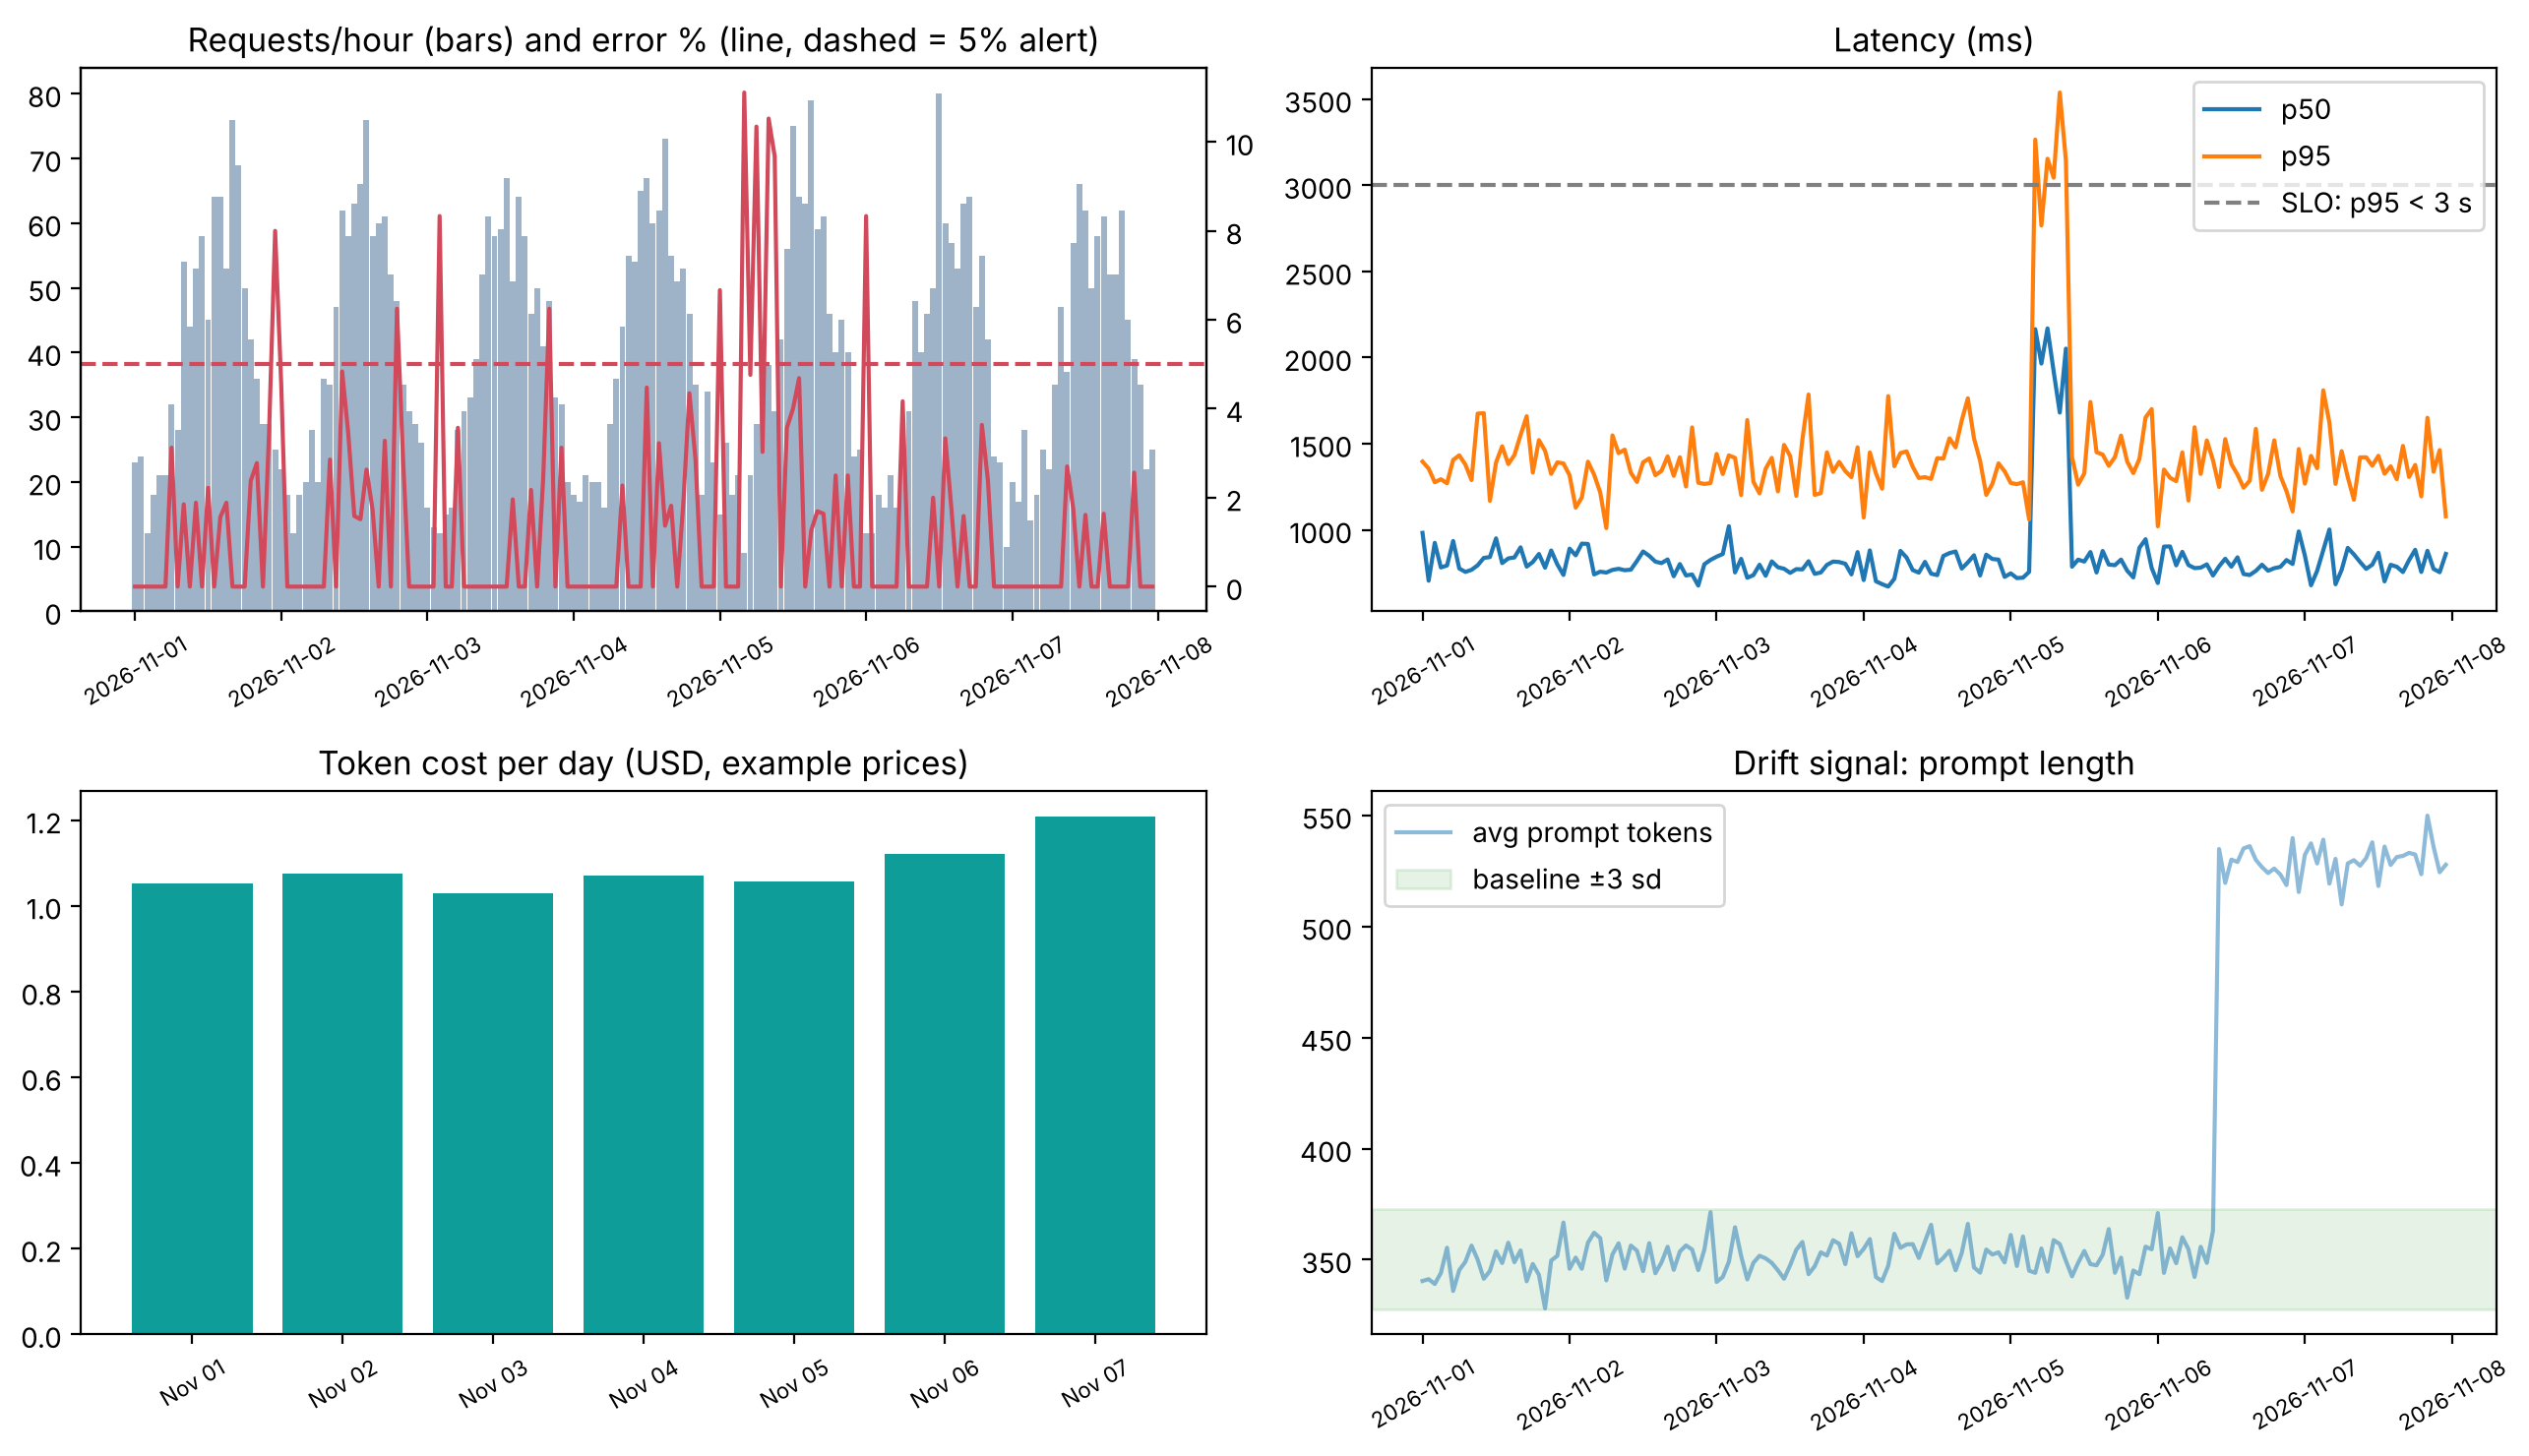

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
a = ax[0, 0]; a.bar(hourly.index, hourly.requests, width=0.04, color="#9fb3c8")
a2 = a.twinx(); a2.plot(hourly.index, hourly.error_rate * 100, color="#d1495b"); a2.axhline(5, ls="--", color="#d1495b")
a.set_title("Requests/hour (bars) and error % (line, dashed = 5% alert)")
b = ax[0, 1]; b.plot(hourly.index, hourly.p50, label="p50"); b.plot(hourly.index, hourly.p95, label="p95")
b.axhline(3000, ls="--", color="grey", label="SLO: p95 < 3 s"); b.legend(); b.set_title("Latency (ms)")
c = ax[1, 0]; daily = hourly.cost_usd.resample("D").sum()
c.bar(daily.index.strftime("%b %d"), daily.values, color="#0f9d9a"); c.set_title("Token cost per day (USD, example prices)")
d = ax[1, 1]; base = hourly.prompt_tokens[:72]
d.plot(hourly.index, hourly.prompt_tokens, alpha=0.5, label="avg prompt tokens")
d.axhspan(base.mean() - 3 * base.std(), base.mean() + 3 * base.std(), color="green", alpha=0.1, label="baseline ±3 sd")
d.legend(); d.set_title("Drift signal: prompt length")
for x in ax.flat: x.tick_params(axis="x", labelrotation=30, labelsize=8)
plt.tight_layout(); plt.show()

## Step 9 — detecting drift with numbers, not eyeballs

Two simple, widely used checks:

- **z-score of the mean**: how many baseline standard deviations the recent average has moved. Above ~3 is suspicious.
- **PSI (Population Stability Index)**: splits values into buckets and compares the share in each bucket between baseline and recent data. Rule of thumb: < 0.1 stable, 0.1–0.25 watch, > 0.25 significant drift.

In [9]:
def psi(baseline, recent, bins=10):
    edges = np.percentile(baseline, np.linspace(0, 100, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    b = np.histogram(baseline, edges)[0] / len(baseline) + 1e-6
    r = np.histogram(recent, edges)[0] / len(recent) + 1e-6
    return float(np.sum((r - b) * np.log(r / b)))

baseline = df[df.time < start + pd.Timedelta(days=3)].tokens_in
for label, lo, hi in [("day 4", 3, 4), ("day 7", 6, 7)]:
    recent = df[(df.time >= start + pd.Timedelta(days=lo)) & (df.time < start + pd.Timedelta(days=hi))].tokens_in
    z = (recent.mean() - baseline.mean()) / baseline.std()
    print(f"{label}: mean prompt {recent.mean():.0f} tokens | z = {z:+.2f} | PSI = {psi(baseline, recent):.3f}")

day 4: mean prompt 353 tokens | z = +0.07 | PSI = 0.022
day 7: mean prompt 530 tokens | z = +4.44 | PSI = 11.615


## Step 10 — alert rules

An **alert** is an automatic message (Slack, email, pager) when a number crosses a threshold. We write each rule as data, then check every hour. Real tools (Grafana, Datadog, cloud monitoring) work the same way, plus a "for at least N minutes" condition to avoid noisy one-off alerts.

In [10]:
RULES = [
    ("error_rate", ">", 0.05, "Error rate above 5% - check provider status, enable fallback"),
    ("p95",        ">", 3000, "p95 latency above 3 s SLO - check provider, prompt size, retries"),
    ("prompt_tokens", ">", base.mean() * 1.25, "Prompt length +25% vs baseline - possible drift, cost rising"),
]
fired = []
for t, row in hourly.iterrows():
    for metric, op, limit, action in RULES:
        if row[metric] > limit:
            fired.append((t, metric, round(row[metric], 3), action))
alerts = pd.DataFrame(fired, columns=["hour", "metric", "value", "action"])
print(alerts.groupby("metric").hour.agg(["count", "min"]))

               count                 min
metric                                  
error_rate        10 2026-11-01 23:00:00
p95                5 2026-11-05 04:00:00
prompt_tokens     38 2026-11-06 10:00:00


**Look closely:** the error-rate rule also fired at night on normal days. At 3 a.m. there are only ~12 requests per hour, so a single failure is already 8%. Real alert rules add a **minimum volume** ("at least 50 requests") or a longer window, otherwise people learn to ignore noisy alerts. Fix it in the exercises.

## Step 11 — a tiny offline eval, attached to traces

An **eval** checks answer *quality*, not just speed. Here: 5 test questions, each with keywords a good answer must contain. Our grader is a keyword check (a stand-in for **LLM-as-judge**, where another model grades the answer). Each score is stored on the trace — the same thing `score_trace` does in Langfuse.

In [11]:
TESTS = [
    ("What is Docker?", ["container", "image"]),
    ("What does p95 mean?", ["95", "slower"]),
    ("Why use async?", ["wait"]),
    ("What is PII?", ["personal"]),
    ("What is CI?", ["test", "automatic"]),
]
CANNED = {   # pretend model answers (one is deliberately weak)
    "What is Docker?": "Docker builds an image and runs it as a container.",
    "What does p95 mean?": "95% of requests are faster; 5% are slower.",
    "Why use async?": "So the server can do other work while it waits.",
    "What is PII?": "It is data.",
    "What is CI?": "Every change is tested automatically.",
}
scores = []
for q, must in TESTS:
    with span("eval-case", question=q) as tr:
        ans = CANNED[q]
        score = sum(w in ans.lower() for w in must) / len(must)
        tr["attrs"]["score"] = score
    scores.append(score)
    print(f"{score:.2f}  {q}")
print(f"\nmean eval score {np.mean(scores):.2f} - in CI you would fail the build below, say, 0.8")

1.00  What is Docker?
1.00  What does p95 mean?
1.00  Why use async?
0.00  What is PII?
1.00  What is CI?

mean eval score 0.80 - in CI you would fail the build below, say, 0.8


## Recap

- A trace is nested, timed records; Langfuse stores and visualises them, adds cost and scores.
- Watch **p50/p95 latency, error rate, cost, drift**; percentiles beat averages.
- Drift checks: mean shift (z-score) and PSI against a baseline period.
- Alerts are rules on metrics; evals put a number on quality and can gate deployments.

**Try it yourself:** add a fourth alert rule for daily cost above a budget, and find which day fires it.